<a href="https://colab.research.google.com/github/ny6in/AIML/blob/main/Data_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ======================================================
# Task 0: Import Required Libraries
# Purpose:
# Import all the libraries required for data preprocessing
# and visualization.
# ======================================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split

from sklearn.impute import SimpleImputer

from sklearn.utils import resample

# Ignore warning messages
import warnings
warnings.filterwarnings("ignore")

In [ ]:
import pandas as pd
import numpy as np

# Load the dataset from the specific path provided
file_path = '/content/netflix_titles.csv'
df = pd.read_csv(file_path)

# 1. Handle Missing Values
# Fill categorical missing values with their respective modes
for col in ['director', 'cast', 'country', 'rating', 'date_added']:
    if df[col].isnull().any():
        df[col].fillna(df[col].mode()[0], inplace=True)

# 2. Remove Duplicates
df.drop_duplicates(inplace=True)

# 3. Handle Outliers in release_year (IQR Method)
Q1 = df['release_year'].quantile(0.25)
Q3 = df['release_year'].quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
df = df[(df['release_year'] >= lower) & (df['release_year'] <= upper)]

# 4. Feature Engineering & Cleaning
# Convert date_added to datetime and strip text spaces
df['date_added'] = pd.to_datetime(df['date_added'].str.strip(), format='mixed')
df['added_year'] = df['date_added'].dt.year

text_cols = df.select_dtypes(include='object').columns
for col in text_cols:
    df[col] = df[col].str.strip()

# 5. Encoding
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
le = LabelEncoder()
df['type_encoded'] = le.fit_transform(df['type'])

# 6. Scaling
scaler = MinMaxScaler()
df['release_year_scaled'] = scaler.fit_transform(df[['release_year']])

print(f"Cleaning Complete. New Shape: {df.shape}")
display(df.head())

Cleaning Complete. New Shape: (8088, 15)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,added_year,type_encoded,release_year_scaled
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,David Attenborough,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021,0,0.941176
1,s2,TV Show,Blood & Water,Rajiv Chilaka,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021,1,1.000000
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",United States,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021,1,1.000000
3,s4,TV Show,Jailbirds New Orleans,Rajiv Chilaka,David Attenborough,United States,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021,1,1.000000
4,s5,TV Show,Kota Factory,Rajiv Chilaka,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021,1,1.000000


In [ ]:
# ### Note on Google Drive
# The local file `/content/netflix_titles.csv` is being used directly.
# Drive mounting is skipped to avoid credential errors.

In [ ]:
# ======================================================
# Task 2: Display Basic Information
# Purpose:
# Find the number of rows, columns, data types,
# and missing values in the dataset.
# ======================================================

# Shape of dataset
print("Shape of Dataset:", df.shape)

# Number of rows
print("Number of Rows:", df.shape[0])

# Number of columns
print("Number of Columns:", df.shape[1])

print("\nData Types")
print(df.dtypes)

print("\nDataset Information")
print(df.info())

print("\nMissing Values")
print(df.isnull().sum())

Shape of Dataset: (8088, 15)
Number of Rows: 8088
Number of Columns: 15

Data Types
show_id                        object
type                           object
title                          object
director                       object
cast                           object
country                        object
date_added             datetime64[ns]
release_year                    int64
rating                         object
duration                       object
listed_in                      object
description                    object
added_year                      int32
type_encoded                    int64
release_year_scaled           float64
dtype: object

Dataset Information
<class 'pandas.core.frame.DataFrame'>
Index: 8088 entries, 0 to 8806
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   show_id              8088 non-null   object        
 1   type                 8088 non-nul

In [ ]:
# ======================================================
# Task 3: Exploratory Data Inspection
# Purpose:
# Display first records, last records,
# and randomly selected records.
# ======================================================

print("First 5 Records")
display(df.head())

print("Last 5 Records")
display(df.tail())

print("Random 5 Records")
display(df.sample(5))

First 5 Records


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,added_year,type_encoded,release_year_scaled
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,David Attenborough,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021,0,0.941176
1,s2,TV Show,Blood & Water,Rajiv Chilaka,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021,1,1.000000
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",United States,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021,1,1.000000
3,s4,TV Show,Jailbirds New Orleans,Rajiv Chilaka,David Attenborough,United States,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021,1,1.000000
4,s5,TV Show,Kota Factory,Rajiv Chilaka,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021,1,1.000000


Last 5 Records


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,added_year,type_encoded,release_year_scaled
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,2019-11-20,2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a...",2019,0,0.176471
8803,s8804,TV Show,Zombie Dumb,Rajiv Chilaka,David Attenborough,United States,2019-07-01,2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g...",2019,1,0.823529
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,2019-11-01,2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...,2019,0,0.294118
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,2020-01-11,2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero...",2020,0,0.117647
8806,s8807,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...",India,2019-03-02,2015,TV-14,111 min,"Dramas, International Movies, Music & Musicals",A scrappy but poor boy worms his way into a ty...,2019,0,0.647059


Random 5 Records


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,added_year,type_encoded,release_year_scaled
2155,s2156,Movie,The Magic School Bus Rides Again Kids In Space,Richard Weston,"Kate McKinnon, Matthew Mucci, Mikaela Blake, G...",United States,2020-08-07,2020,TV-Y,46 min,Children & Family Movies,The Magic School Bus kids blast into orbit — a...,2020,0,0.941176
4632,s4633,TV Show,The Good Cop,Rajiv Chilaka,"Tony Danza, Josh Groban, Monica Barbaro, Isiah...",United States,2018-09-21,2018,TV-14,1 Season,"Crime TV Shows, TV Comedies, TV Dramas","When he's not solving murders, a pathologicall...",2018,1,0.823529
5755,s5756,Movie,Mascots,Christopher Guest,"Carrie Aizley, Sarah Baker, Bob Balaban, Ed Be...",United States,2016-10-13,2016,TV-MA,95 min,Comedies,Eager contestants don big heads and furry suit...,2016,0,0.705882
6714,s6715,TV Show,Everyday Miracles,Rajiv Chilaka,Mark Miodownik,United Kingdom,2017-08-01,2014,TV-PG,1 Season,"British TV Shows, Docuseries, International TV...",Materials scientist Mark Miodownik takes us in...,2017,1,0.588235
7309,s7310,Movie,Lion's Heart,Karim El Sobky,"Mohamed Ramadan, Hassan Hosny, Horeya Farghaly...",Egypt,2019-05-09,2013,TV-14,111 min,"Action & Adventure, International Movies","Kidnapped as a child and raised in the circus,...",2019,0,0.529412


In [ ]:
# ======================================================
# Task 4: Detect Missing Values
# ======================================================

df.isnull().sum()

,0
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,0
release_year,0
rating,0
duration,3


In [ ]:
# ======================================================
# Task 4: Handle Missing Values
# Purpose:
# Fill missing categorical values using Mode.
# ======================================================

# Fill missing values with mode
df["director"].fillna(df["director"].mode()[0], inplace=True)
df["cast"].fillna(df["cast"].mode()[0], inplace=True)
df["country"].fillna(df["country"].mode()[0], inplace=True)
df["rating"].fillna(df["rating"].mode()[0], inplace=True)
df["date_added"].fillna(df["date_added"].mode()[0], inplace=True)

print(df.isnull().sum())

show_id                0
type                   0
title                  0
director               0
cast                   0
country                0
date_added             0
release_year           0
rating                 0
duration               3
listed_in              0
description            0
added_year             0
type_encoded           0
release_year_scaled    0
dtype: int64


In [ ]:
# ======================================================
# Task 5: Detect and Remove Duplicate Records
# ======================================================

print("Duplicate Records:", df.duplicated().sum())

df.drop_duplicates(inplace=True)

print("Duplicate Records After Removal:", df.duplicated().sum())

Duplicate Records: 0
Duplicate Records After Removal: 0


In [ ]:
# ======================================================
# Task 6: Detect Outliers Using IQR
# Purpose:
# Identify outliers in release_year.
# ======================================================

Q1 = df["release_year"].quantile(0.25)
Q3 = df["release_year"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df["release_year"] < lower) | (df["release_year"] > upper)]

print("Number of Outliers:", len(outliers))

Number of Outliers: 464


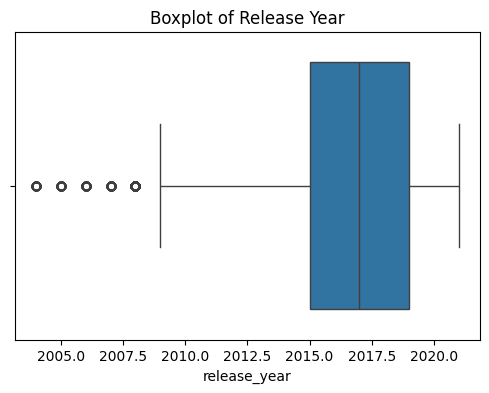

In [ ]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df["release_year"])
plt.title("Boxplot of Release Year")
plt.show()

In [ ]:
# ======================================================
# Task 7: Remove Outliers
# ======================================================

df = df[(df["release_year"] >= lower) &
        (df["release_year"] <= upper)]

print(df.shape)

(7624, 15)


In [ ]:
# ======================================================
# Task 8A: Label Encoding
# ======================================================

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df["type_encoded"] = le.fit_transform(df["type"])

df[["type","type_encoded"]].head()

,type,type_encoded
0,Movie,0
1,TV Show,1
2,TV Show,1
3,TV Show,1
4,TV Show,1


In [ ]:
# Task 8B: One-Hot Encoding
# Using the cleaned dataframe 'df'
encoded_df = pd.get_dummies(df, columns=["rating"], drop_first=True)
print("One-Hot Encoding complete.")
display(encoded_df.head())

One-Hot Encoding complete.


,show_id,type,title,director,cast,country,date_added,release_year,duration,listed_in,...,rating_PG-13,rating_R,rating_TV-14,rating_TV-G,rating_TV-MA,rating_TV-PG,rating_TV-Y,rating_TV-Y7,rating_TV-Y7-FV,rating_UR
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,David Attenborough,United States,2021-09-25,2020,90 min,Documentaries,...,True,False,False,False,False,False,False,False,False,False
1,s2,TV Show,Blood & Water,Rajiv Chilaka,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries",...,False,False,False,False,True,False,False,False,False,False
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",United States,2021-09-24,2021,1 Season,"Crime TV Shows, International TV Shows, TV Act...",...,False,False,False,False,True,False,False,False,False,False
3,s4,TV Show,Jailbirds New Orleans,Rajiv Chilaka,David Attenborough,United States,2021-09-24,2021,1 Season,"Docuseries, Reality TV",...,False,False,False,False,True,False,False,False,False,False
4,s5,TV Show,Kota Factory,Rajiv Chilaka,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",...,False,False,False,False,True,False,False,False,False,False


In [ ]:
# ======================================================
# Task 9A: Min-Max Scaling
# ======================================================

scaler = MinMaxScaler()

df["release_year_minmax"] = scaler.fit_transform(
    df[["release_year"]]
)

df[["release_year","release_year_minmax"]].head()

,release_year,release_year_minmax
0,2020,0.916667
1,2021,1.000000
2,2021,1.000000
3,2021,1.000000
4,2021,1.000000


In [ ]:
# ======================================================
# Task 9B: Standardization (Z-score)
# ======================================================

std = StandardScaler()

df["release_year_standard"] = std.fit_transform(
    df[["release_year"]]
)

df[["release_year","release_year_standard"]].head()

,release_year,release_year_standard
0,2020,1.049311
1,2021,1.389199
2,2021,1.389199
3,2021,1.389199
4,2021,1.389199


In [ ]:
# ======================================================
# Task 10: Feature Selection
# Purpose:
# Find correlation between numerical columns.
# ======================================================

numeric_df = df.select_dtypes(include=np.number)

numeric_df.corr()

,release_year,added_year,type_encoded,release_year_scaled,release_year_minmax,release_year_standard
release_year,1.000000,0.414713,0.167281,1.000000,1.000000,1.000000
added_year,0.414713,1.000000,0.058345,0.414713,0.414713,0.414713
type_encoded,0.167281,0.058345,1.000000,0.167281,0.167281,0.167281
release_year_scaled,1.000000,0.414713,0.167281,1.000000,1.000000,1.000000
release_year_minmax,1.000000,0.414713,0.167281,1.000000,1.000000,1.000000
release_year_standard,1.000000,0.414713,0.167281,1.000000,1.000000,1.000000


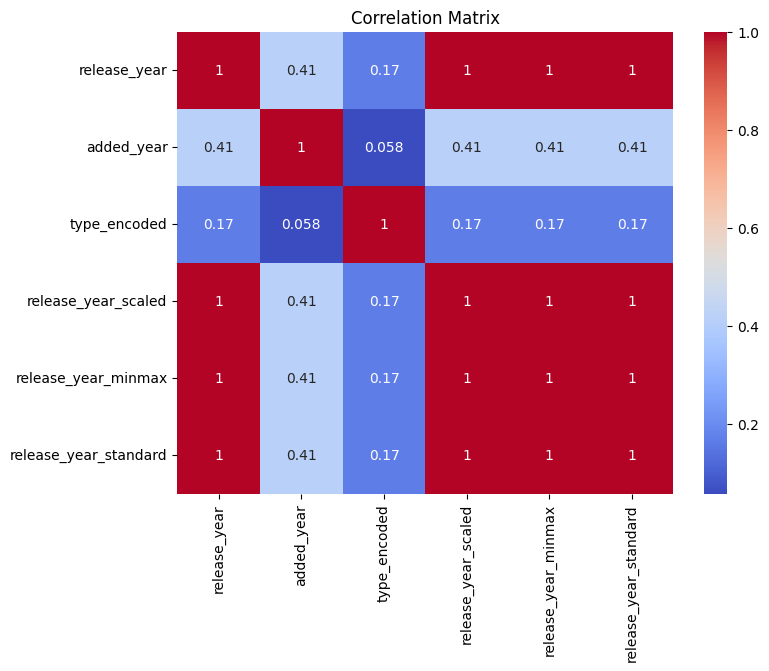

In [ ]:
# ======================================================
# Task 11: Correlation Heatmap
# ======================================================

plt.figure(figsize=(8,6))

sns.heatmap(numeric_df.corr(),
            annot=True,
            cmap="coolwarm")

plt.title("Correlation Matrix")
plt.show()

In [ ]:
# ======================================================
# Task 12: Create New Feature
# Purpose:
# Extract the year from date_added.
# ======================================================

df["date_added"] = pd.to_datetime(df["date_added"], format='mixed')

df["added_year"] = df["date_added"].dt.year

df[["date_added","added_year"]].head()

,date_added,added_year
0,2021-09-25,2021
1,2021-09-24,2021
2,2021-09-24,2021
3,2021-09-24,2021
4,2021-09-24,2021


In [ ]:
# ======================================================
# Task 13: Convert Data Types
# ======================================================

df["release_year"] = df["release_year"].astype(float)

print(df.dtypes)

show_id                          object
type                             object
title                            object
director                         object
cast                             object
country                          object
date_added               datetime64[ns]
release_year                    float64
rating                           object
duration                         object
listed_in                        object
description                      object
added_year                        int32
type_encoded                      int64
release_year_scaled             float64
release_year_minmax             float64
release_year_standard           float64
dtype: object


In [ ]:
# ======================================================
# Task 14: Handle Inconsistent Data
# Purpose:
# Remove extra spaces from text columns.
# ======================================================

text_columns = df.select_dtypes(include="object").columns

for col in text_columns:
    df[col] = df[col].str.strip()

df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,added_year,type_encoded,release_year_scaled,release_year_minmax,release_year_standard
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,David Attenborough,United States,2021-09-25,2020.0,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021,0,0.941176,0.916667,1.049311
1,s2,TV Show,Blood & Water,Rajiv Chilaka,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021.0,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021,1,1.000000,1.000000,1.389199
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",United States,2021-09-24,2021.0,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021,1,1.000000,1.000000,1.389199
3,s4,TV Show,Jailbirds New Orleans,Rajiv Chilaka,David Attenborough,United States,2021-09-24,2021.0,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021,1,1.000000,1.000000,1.389199
4,s5,TV Show,Kota Factory,Rajiv Chilaka,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021.0,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021,1,1.000000,1.000000,1.389199


In [ ]:
# ======================================================
# Task 15: Split Dataset
# ======================================================

X = df[["release_year"]]

y = df["type_encoded"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(6099, 1)
(1525, 1)


In [ ]:
# ======================================================
# Task 16: Random Oversampling
# Purpose:
# Balance Movie and TV Show classes.
# ======================================================

movie = df[df["type"]=="Movie"]
tv = df[df["type"]=="TV Show"]

tv_upsampled = resample(tv,
                        replace=True,
                        n_samples=len(movie),
                        random_state=42)

balanced_df = pd.concat([movie,tv_upsampled])

balanced_df["type"].value_counts()

,count
type,
Movie,5096
TV Show,5096


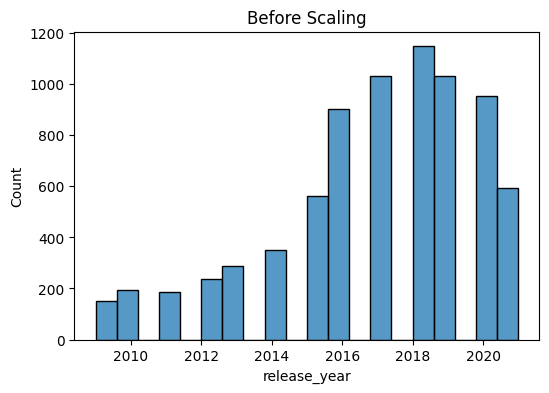

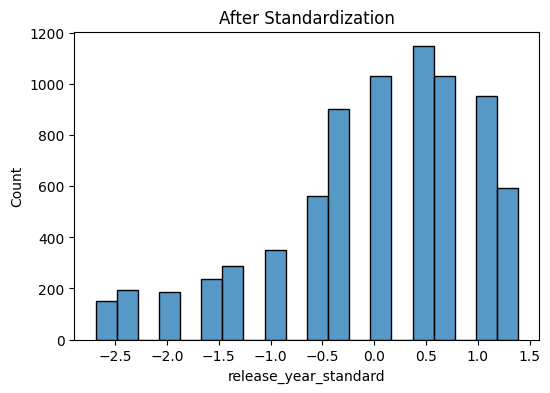

In [ ]:
# ======================================================
# Task 17: Distribution Comparison
# ======================================================

plt.figure(figsize=(6,4))
sns.histplot(df["release_year"], bins=20)
plt.title("Before Scaling")
plt.show()

plt.figure(figsize=(6,4))
sns.histplot(df["release_year_standard"], bins=20)
plt.title("After Standardization")
plt.show()

In [ ]:
# ======================================================
# Task 18: Compare Dataset Before and After Cleaning
# ======================================================

print("Original Shape:", (8807,12))
print("Processed Shape:", df.shape)

print("\nMissing Values After Cleaning")
print(df.isnull().sum())

print("\nDuplicate Records")
print(df.duplicated().sum())

Original Shape: (8807, 12)
Processed Shape: (7624, 17)

Missing Values After Cleaning
show_id                  0
type                     0
title                    0
director                 0
cast                     0
country                  0
date_added               0
release_year             0
rating                   0
duration                 3
listed_in                0
description              0
added_year               0
type_encoded             0
release_year_scaled      0
release_year_minmax      0
release_year_standard    0
dtype: int64

Duplicate Records
0


In [ ]:
# Task 19: Save Cleaned Dataset
# Saving to local Colab storage
df.to_csv("cleaned_netflix_titles.csv", index=False)
print("Cleaned dataset saved as 'cleaned_netflix_titles.csv' in the local /content/ directory.")

Cleaned dataset saved as 'cleaned_netflix_titles.csv' in the local /content/ directory.


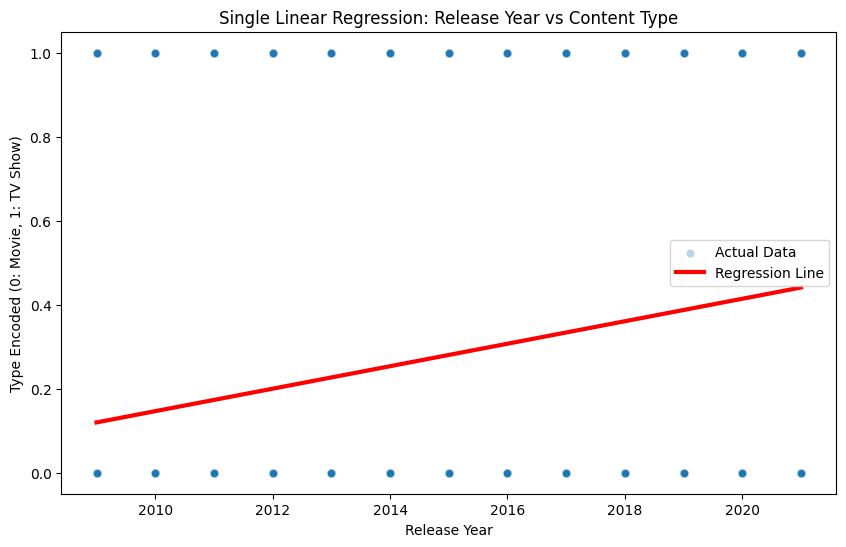

R^2 Score (Single): 0.0280


In [ ]:
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import numpy as np

# --- Single Linear Regression ---
# Features (X) and Target (y)
X_single = df[['release_year']]
y = df['type_encoded']

model_single = LinearRegression()
model_single.fit(X_single, y)

# Prediction for plotting
X_range = np.linspace(X_single.min(), X_single.max(), 100).reshape(-1, 1)
y_pred_single = model_single.predict(X_range)

# Visualization
plt.figure(figsize=(10, 6))
sns.scatterplot(x='release_year', y='type_encoded', data=df, alpha=0.3, label='Actual Data')
plt.plot(X_range, y_pred_single, color='red', linewidth=3, label='Regression Line')
plt.title('Single Linear Regression: Release Year vs Content Type')
plt.xlabel('Release Year')
plt.ylabel('Type Encoded (0: Movie, 1: TV Show)')
plt.legend()
plt.show()

print(f'R^2 Score (Single): {model_single.score(X_single, y):.4f}')

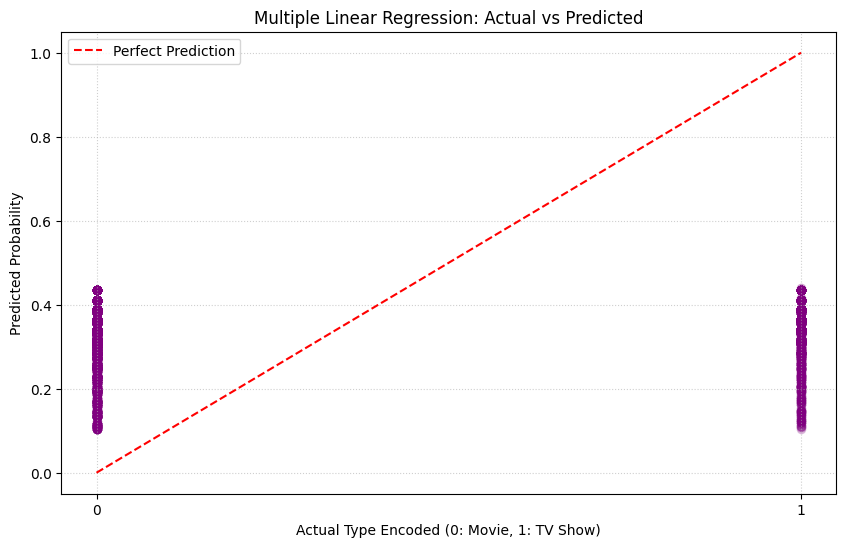

R^2 Score (Multiple Regression): 0.0281


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

# Define features and target for multiple regression
X_multi = df[['release_year', 'added_year']]
y_multi = df['type_encoded']

# Create and train the multiple linear regression model
model_multi = LinearRegression()
model_multi.fit(X_multi, y_multi)

# Calculate predictions using the multiple regression model
y_pred_multi = model_multi.predict(X_multi)

# Visualization: Actual vs Predicted
plt.figure(figsize=(10, 6))
plt.scatter(y_multi, y_pred_multi, alpha=0.1, color='purple')

# Add a diagonal line for reference (where predicted = actual)
plt.plot([y_multi.min(), y_multi.max()], [y_multi.min(), y_multi.max()], color='red', linestyle='--', label='Perfect Prediction')

plt.title('Multiple Linear Regression: Actual vs Predicted')
plt.xlabel('Actual Type Encoded (0: Movie, 1: TV Show)')
plt.ylabel('Predicted Probability')
plt.xticks([0, 1])
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

print(f'R^2 Score (Multiple Regression): {model_multi.score(X_multi, y_multi):.4f}')

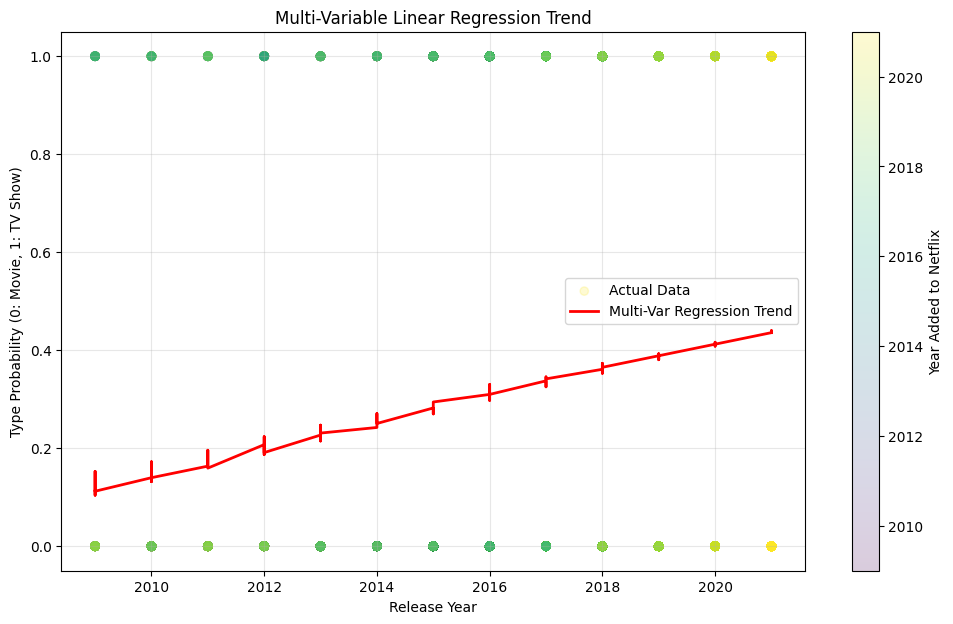

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare data for plotting
plot_df = X_multi.copy()
plot_df['Actual'] = y_multi
plot_df['Predicted'] = model_multi.predict(X_multi)

plt.figure(figsize=(12, 7))
# Plotting release_year vs Actual, colored by added_year
scatter = plt.scatter(plot_df['release_year'], plot_df['Actual'],
            c=plot_df['added_year'], cmap='viridis', alpha=0.2, label='Actual Data')

# Sorting for a clean regression line plot
sorted_df = plot_df.sort_values(by='release_year')
plt.plot(sorted_df['release_year'], sorted_df['Predicted'], color='red', linewidth=2, label='Multi-Var Regression Trend')

cbar = plt.colorbar(scatter)
cbar.set_label('Year Added to Netflix')

plt.title('Multi-Variable Linear Regression Trend')
plt.xlabel('Release Year')
plt.ylabel('Type Probability (0: Movie, 1: TV Show)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()